# Implementation of TMSE-BioCRNpyler Modules Across Contexts

**Installing and Initializing Modules**
Please refer to the [README](https://github.com/usnistgov/TMSE_BioCRNpyler_Library/blob/main/README.md) for detailed installation instructions and further documentation.

The following sections highlight the core capabilities of the TMSE-BioCRNpyler modules by demonstrating how to compile and simulate published examples. Each section is broken down into two main steps: The first code block integrates standard BioCRNpyler components, mechanisms, and mixtures seamlessly with the new TMSE modules to generate a chemical reaction network (CRN). The second code block simulates the compiled CRN using BioSCRAPE across various initial conditions.

### Figure 4 Simulations: Simulating ctRSD circuits across environments
This section recreates the simulations from Figure 4, utilizing the `MaturationO1()`, `OneStepTMSE()`, and `GateTXLeak()` mechanisms across different biological contexts:
* Figure 4A
    * [IVT conditions](#Genetically-encoded-RNA-based-TMSE-circuits-in-IVT)
* Figure 4B
    * [Cell-free conditions](#Genetically-encoded-RNA-based-TMSE-circuits-in-TX-TL-(PURE))
    * [Extract TX-TL conditions](#Genetically-encoded-RNA-based-TMSE-circuits-in-extract-TX-TL-(E-coli-lysate))
* Figure 4C: In-cell-conditions
    * [SimpleTxTlDilutionMixture()](#Genetically-encoded-RNA-based-TMSE-circuits-in-cells-(E-coli---SimpleTxTlDilutionMixture))
    * [TxTlDilutionMixture()](#Genetically-encoded-RNA-based-TMSE-circuits-in-cells-(E-coli---TxTlDilutionMixture)) 


## Dependencies and packages

In [1]:
from biocrnpyler import *
import numpy as np
import pylab as plt
from pathlib import Path
from matplotlib.gridspec import GridSpec


# Get base directory for BioCRNpyler scripts
directory = Path.cwd()
for p in [directory, *directory.parents]:
    if p.name == 'TMSE_BioCRNpyler_Library':
        base_dir = p
        break

# Location of scripts
tmse_mechs = (base_dir / 'mechanisms' / 'ToeholdMediatedStrandExchange.py').as_posix()
tmse_comps = (base_dir / 'components' / 'ToeholdMediatedStrandExchange.py').as_posix()
rna_comp = (base_dir / 'components' / 'RNAassembly.py').as_posix()

# Run scripts
%run {tmse_mechs}
%run {tmse_comps}
%run {rna_comp}

# Directory for Figures and Data
figs_dir = (base_dir / 'figures').as_posix()
data_dir = (base_dir / 'data').as_posix()

## Global variables and definitions

In [2]:
# Simulate all models - example for 3 hours
timepoints = np.linspace(0,4,5001)*3600 

# Set a global default size for plots
plt.rcParams["figure.figsize"] = (6, 6)
font = 'MS Reference Sans Serif'
plt.rcParams["svg.fonttype"] = "none"
plt.rcParams['font.sans-serif'] = ['MS Reference Sans Serif']


#Definition to un-nest lists that will be created by models
def flatten(t):
    return [item for sublist in t for item in sublist]

# Plotting format
def FormatPlot(ylabel, fig_name, ymin = -0.02, ymax = 100):
    fs = 20
    
    plt.ylabel(ylabel,fontsize=fs)
    plt.xlabel('Time (h)',fontsize=fs)
    plt.legend(title='Input',frameon=False, 
               title_fontsize = fs-5, fontsize=fs-5)

    plt.ylim(ymin,ymax)
    plt.xlim(0,4)
    plt.xticks(ticks=[0,1,2,3,4],fontsize=fs)
    if ymax < 1:
        plt.yticks(ticks=[0.0,0.1,0.2,0.3,0.4,0.5],fontsize=fs)
    else:
        plt.yticks(ticks=[0,2,4,6,8],fontsize=fs)

    # Save plot as svg
    plt.savefig(f'{figs_dir}/SI_{fig_name}.svg')

# Genetically encoded RNA-based TMSE circuits in IVT

A simulation of a ctRSD circuits from Design Approaches to Expand the Toolkit for Building Cotranscriptionally Encoded RNA Strand Displacement Circuits ([Schaffter et al. *ACS Synthetic Biology* 2023](https://pubs.acs.org/doi/10.1021/acssynbio.3c00079)). 



In [3]:
# Define initial DNA and Reporter RNA
sim_inputs = {'I{1,}': ['Input',1]} # Input DNA
sim_gates = {'G{1,2}':['Gate',1,2]} # Gate DNA
sim_reporter = {'R{2,}':['Reporter',2]} # Reporter DNA

# Components
step_tx0 = StrandExchangeMol(sim_inputs, material_type= 'dna', transcription=True)
step_tx1 = StrandExchangeMol(sim_gates, material_type= 'dna', transcription=True, rna_maturation=True,leak='ctRSDleak')
step_tx2 =StrandExchangeMol(sim_reporter, material_type = 'dna')

step_mat =RNAmaturation(step_tx1)

rna_TMSE = step_tx0.rna+ step_tx1.rna+ step_tx2.mol+ step_mat.rna
step_sd = TMSE(rna_TMSE)
step_leak = LeakctRSD(step_tx1)

# Reactions
# # Mechanism tx 
mech_tx = mech_tl = SimpleTranscription()
tx_mechanisms = {mech_tx.mechanism_type:mech_tx}
# Mechanism rz
mech_mat = MaturationO1()
mat_mechanisms = {mech_mat.mechanism_type: mech_mat}
# Mechanism strand displacement
mech_sd = OneStepTMSE()
sd_mechanisms = {mech_sd.mechanism_type:mech_sd}
# Mechanism leak
mech_leak = GateTxLeak()
leak_mechanisms = {mech_leak.mechanism_type:mech_leak}

parameters_ORctRSD = {"ktx":.013,
                      "leak_percentage":0.03, 
                      "kmat": 0.00417, 
                      "kx":1e-6, 
                      "krev":270e-9, 
                      "krep":1e4/1e9
                      }

# Make Mixture and Compile
M_OR = Mixture("IVT_ctRSD", 
               components=[step_tx0.mol, step_tx1.mol, step_mat, step_sd, step_leak],
               parameters=parameters_ORctRSD,
               mechanisms=tx_mechanisms|mat_mechanisms|sd_mechanisms|leak_mechanisms)

# Compile the CRN with Mixture.compile_crn
CRN_OR = M_OR.compile_crn()

print(CRN_OR.pretty_print(show_rates = True, show_attributes = True,
                          show_materials = True, show_keys = False))

Species(N = 11) = {
dna[Signal_2(ss)] (@ 0),  dna[Reporter_2] (@ 0),  rnadna[ReporterOut_2] (@ 0),  rna[Output_1_2] (@ 0),  rna[Output_1_2(dummy)] (@ 0),  rna[Input_1] (@ 0),  dna[Input_1] (@ 0),  rna[Gate_1_2] (@ 0),  rna[Gate_1_2(pre)] (@ 0),  dna[Gate_1_2] (@ 0),  rna[GateOut_1_1] (@ 0),  
}

Reactions (6) = [
0. dna[Input_1] --> dna[Input_1]+rna[Input_1]
 Kf=k_forward * dna_Input_1
  k_forward=0.013

1. dna[Gate_1_2] --> dna[Gate_1_2]+rna[Gate_1_2(pre)]+rna[Output_1_2(dummy)]
 Kf=k_forward * dna_Gate_1_2
  k_forward=0.013

2. rna[Gate_1_2(pre)] --> rna[Gate_1_2]
 Kf=k_forward * rna_Gate_1_2_pre
  k_forward=0.00417

3. rna[Gate_1_2]+rna[Input_1] <--> rna[Output_1_2]+rna[GateOut_1_1]
 Kf=k_forward * rna_Gate_1_2 * rna_Input_1
 Kr=k_reverse * rna_Output_1_2 * rna_GateOut_1_1
  k_forward=1e-06
  k_reverse=2.7e-07

4. rna[Output_1_2]+dna[Reporter_2] --> dna[Signal_2(ss)]+rnadna[ReporterOut_2]
 Kf=k_forward * rna_Output_1_2 * dna_Reporter_2
  k_forward=1e-05

5. 3rna[Gate_1_2(pre)]+100rn

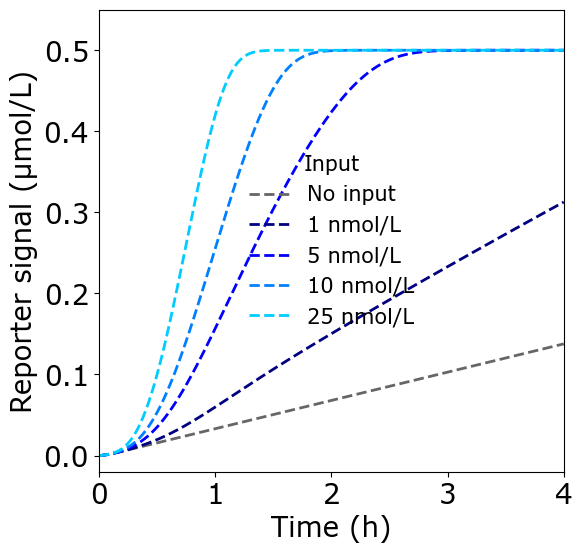

In [4]:
# Simulate
try:
    import pylab as plt

    # Input templates
    IN1 = [0,1,5,10,25]

    idx_conditions = {'No input':[[0.4,0.4,0.4], '--'],
                      '1 nmol/L': [[0,0,0.5],'--'],
                      '5 nmol/L': [[0,0,1],'--'],
                      '10 nmol/L': [[0,0.5,1],'--'],
                      '25 nmol/L': [[0,0.8,1],'--']}

    for I1_conc, key in zip(IN1, idx_conditions.keys()):
        # Create an initial condition so A has a non-zero value
        initial_concentration_dict = {'dna_Input_1': I1_conc,
                                      'dna_Gate_1_2':25,
                                      'dna_Reporter_2':500}
        
        # This function can also take a filename keyword to save the file at the same time
        R = CRN_OR.simulate_with_bioscrape_via_sbml(timepoints = timepoints,
                                                    initial_condition_dict = initial_concentration_dict)
        
        # Results are in a Pandas Dictionary and can be accessed via string-names of species
        plt.plot(R['time']/3600, R['dna_Signal_2_ss']/1000, label = key,
                 color = idx_conditions[key][0], linewidth = 2, linestyle = idx_conditions[key][1])
        
    
except ModuleNotFoundError:
    print("Plotting Modules not installed.")

FormatPlot(ylabel='Reporter signal (μmol/L)',ymax = 0.55, fig_name= 'Figure_2E_IVT')   

## Genetically encoded RNA-based TMSE circuits in TX-TL (PURE)

A simulation of a THE riboregulator from: https://www.biorxiv.org/content/10.1101/2025.09.25.678518v2.full. 

In [5]:
# Define initial DNA and Reporter RNA
sim_inputs = {'DNA_1': ['Input', 1]} # Input DNA
sim_gates = {'DNA_2':['THErr',1,[2,'GFP']]} # Gate DNA
sim_reporter = {'R{2,}':['Reporter',2]} # Reporter DNA

# Components
step_tx0 =StrandExchangeMol(sim_inputs, material_type = 'dna', transcription=True)
step_tx1 =StrandExchangeMol(sim_gates, material_type = 'dna', transcription=True, rna_maturation = True,leak='ctRSDleak')
step_tx2 =StrandExchangeMol(sim_reporter, material_type = 'dna')

step_rz =RNAmaturation(step_tx1)

rna_TMSE = step_tx0.rna+ step_tx1.rna+ step_tx2.mol+ step_rz.rna
step_rsd = TMSE(rna_TMSE)
step_leak = LeakctRSD(step_tx1)

# Reactions
# Mechanism tx 
mech_tx = SimpleTranscription()
tx_mechanisms = {mech_tx.mechanism_type:mech_tx}
# Mechanism rz
mech_rz = MaturationO1()
rz_mechanisms = {mech_rz.mechanism_type: mech_rz}
# Mechanism strand displacement
mech_rsd = OneStepTMSE()
rsd_mechanisms = {mech_rsd.mechanism_type:mech_rsd}
# Mechanism leak
mech_leak = GateTxLeak()
leak_mechanisms = {mech_leak.mechanism_type:mech_leak}
# Mechanism translation
mech_tl = SimpleTranslation()
tl_mechanisms = {mech_tl.mechanism_type:mech_tl}

# Parameters
ctRSD_parameters = {"ktx": 0.013, "leak_percentage": 0.03, "kmat": 0.00417, 
                    "kx":1e-06, "krev":2.7e-07, "krep":1e4/1e9, "ktl":.0005,} 

# Make Mixture and Compile
M_ctRSD = Mixture("Single_Gate_ctRSD", components=[step_tx0.mol, step_tx1.mol, step_rz,step_rsd,step_leak, step_rsd.transcripts],
             parameters=ctRSD_parameters,
             mechanisms=tx_mechanisms|rz_mechanisms|rsd_mechanisms|leak_mechanisms|tl_mechanisms)

# Compile the CRN with Mixture.compile_crn
CRN_ctRSD = M_ctRSD.compile_crn()

# Print CRN reactions
print(CRN_ctRSD.pretty_print(show_rates = True, show_attributes = True, 
                       show_materials = True, show_keys = False))

Species(N = 12) = {
rna[THErr_1_2nGFP] (@ 0),  rna[THErr_1_2nGFP(pre)] (@ 0),  dna[THErr_1_2nGFP] (@ 0),  dna[Signal_2(ss)] (@ 0),  dna[Reporter_2] (@ 0),  rnadna[ReporterOut_2] (@ 0),  rna[Output_1_2nGFP(dummy)] (@ 0),  rna[Output_1_2] (@ 0),  rna[Input_1] (@ 0),  dna[Input_1] (@ 0),  protein[GFP] (@ 0),  rna[GFP] (@ 0),  
}

Reactions (7) = [
0. dna[Input_1] --> dna[Input_1]+rna[Input_1]
 Kf=k_forward * dna_Input_1
  k_forward=0.013

1. dna[THErr_1_2nGFP] --> dna[THErr_1_2nGFP]+rna[THErr_1_2nGFP(pre)]+rna[Output_1_2nGFP(dummy)]
 Kf=k_forward * dna_THErr_1_2nGFP
  k_forward=0.013

2. rna[THErr_1_2nGFP(pre)] --> rna[THErr_1_2nGFP]
 Kf=k_forward * rna_THErr_1_2nGFP_pre
  k_forward=0.00417

3. rna[Input_1]+rna[THErr_1_2nGFP] <--> rna[GFP]+rna[Output_1_2]
 Kf=k_forward * rna_Input_1 * rna_THErr_1_2nGFP
 Kr=k_reverse * rna_GFP * rna_Output_1_2
  k_forward=1e-06
  k_reverse=2.7e-07

4. rna[Output_1_2]+dna[Reporter_2] --> dna[Signal_2(ss)]+rnadna[ReporterOut_2]
 Kf=k_forward * rna_Output_1_2

### Simulated using BioSCRAPE

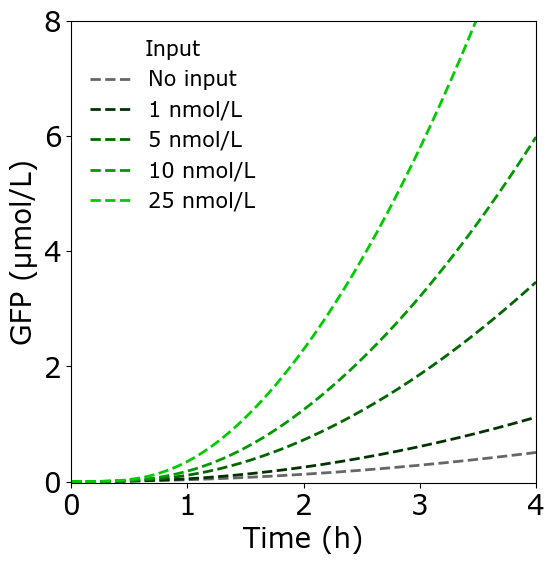

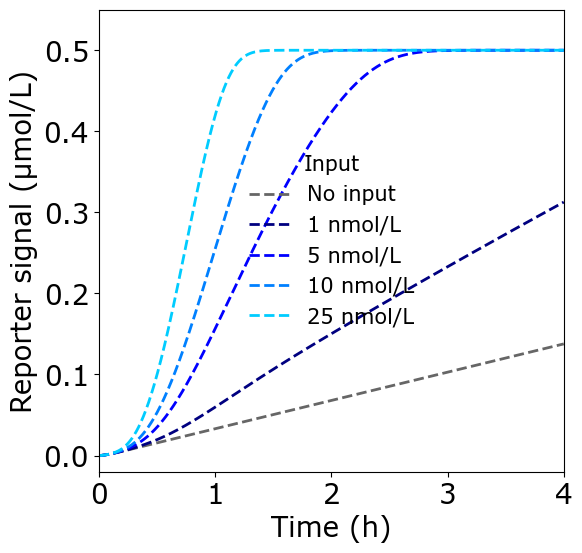

In [6]:
# Simulate
try:
    # Input templates
    IN1 = [0,1,5,10,25]

    idx_conditions = {'No input':[[0.4,0.4,0.4], '--'],
                      '1 nmol/L': [[0,0.2,0],'--'],
                      '5 nmol/L': [[0,0.4,0],'--'],
                      '10 nmol/L': [[0,0.6,0],'--'],
                      '25 nmol/L': [[0,0.8,0],'--']}

    for I1_conc, key in zip(IN1,idx_conditions.keys()):
        # Create an initial condition so A has a non-zero value
        initial_concentration_dict = {'dna_Input_1': I1_conc, 
                                      'dna_THErr_1_2nGFP':25,
                                      'dna_Reporter_2':500}
        
        # This function can also take a filename keyword to save the file at the same time
        R = CRN_ctRSD.simulate_with_bioscrape_via_sbml(timepoints = timepoints,
                                                    initial_condition_dict = initial_concentration_dict)
    
        # Example plotting in the subplots
        plt.plot(R['time']/3600, R['protein_GFP']/1000, label = key,
                 color = idx_conditions[key][0], linewidth = 2, linestyle = idx_conditions[key][1])
    
except ModuleNotFoundError:
    print("Plotting Modules not installed.")

FormatPlot(ylabel='GFP (μmol/L)',ymax = 8, fig_name= 'Figure_2E_PURE_GFP')

try:

    idx_conditions = {'No input':[[0.4,0.4,0.4], '--'],
                      '1 nmol/L': [[0,0,0.5],'--'],
                      '5 nmol/L': [[0,0,1],'--'],
                      '10 nmol/L': [[0,0.5,1],'--'],
                      '25 nmol/L': [[0,0.8,1],'--']}

    for I1_conc, key in zip(IN1,idx_conditions.keys()):
            # Create an initial condition so A has a non-zero value
            initial_concentration_dict = {'dna_Input_1': I1_conc, 
                                        'dna_THErr_1_2nGFP':25,
                                        'dna_Reporter_2':500}
            
            # This function can also take a filename keyword to save the file at the same time
            R = CRN_ctRSD.simulate_with_bioscrape_via_sbml(timepoints = timepoints,
                                                        initial_condition_dict = initial_concentration_dict)
        
            # Example plotting in the subplots
            plt.figure(2)
            plt.plot(R['time']/3600, R['dna_Signal_2_ss']/1000, label = key,
                    color = idx_conditions[key][0], linewidth = 2, linestyle = idx_conditions[key][1])
    
except ModuleNotFoundError:
    print("Plotting Modules not installed.")

FormatPlot(ylabel='Reporter signal (μmol/L)',ymax = 0.55, fig_name= 'Figure_2E_PURE_MB')

## Genetically encoded RNA-based TMSE circuits in extract TX-TL (E coli lysate)

A simulation of a THE riboregulator from: https://www.biorxiv.org/content/10.1101/2025.09.25.678518v2.full. 

In [7]:

# Define initial DNA and Reporter RNA
sim_inputs = {'DNA_1': ['Input', 1]} # Input DNA
sim_gates = {'DNA_2':['THErr',1,[2,'GFP']]} # Gate DNA
sim_reporter = {'R{2,}':['Reporter',2]} # Reporter DNA

# Components
step_tx0 =StrandExchangeMol(sim_inputs, material_type = 'dna', transcription=True)
step_tx1 =StrandExchangeMol(sim_gates, material_type = 'dna', transcription=True, rna_maturation = True, leak='ctRSDleak')
step_tx2 =StrandExchangeMol(sim_reporter, material_type = 'dna')

step_rz =RNAmaturation(step_tx1)

rna_TMSE = step_tx0.rna + step_tx1.rna +step_tx2.mol + step_rz.rna
step_rsd = TMSE(rna_TMSE)
step_leak = LeakctRSD(step_tx1)

# Reactions
# Mechanism rz
mech_rz = MaturationO1()
rz_mechanisms = {mech_rz.mechanism_type: mech_rz}
# Mechanism strand displacement
mech_rsd = OneStepTMSE()
rsd_mechanisms = {mech_rsd.mechanism_type:mech_rsd}
# Mechanism leak
mech_leak = GateTxLeak()
leak_mechanisms = {mech_leak.mechanism_type:mech_leak}
# Mechanism translation

# Parameters
ctRSD_parameters = {"ktx": 0.013, "leak_percentage": 0.03, "kmat": 0.00417, 
                    "kx":1e-06, "krev":2.7e-07, "krep":1e4/1e9, "ktl":.0005,"kdil":0.00025} 

# Make Mixture and Compile
M_ctRSD = SimpleTxTlExtract("Single_Gate_ctRSD_lysate", components=[step_tx0.mol, step_tx1.mol, step_rz,step_rsd,step_leak, step_rsd.transcripts],
             parameters=ctRSD_parameters,
             mechanisms=rz_mechanisms|rsd_mechanisms|leak_mechanisms) #tx_mechanisms|tl_mechanisms

# Compile the CRN with Mixture.compile_crn
CRN_ctRSD = M_ctRSD.compile_crn()

# Print CRN reactions
print(CRN_ctRSD.pretty_print(show_rates = True, show_attributes = True, 
                       show_materials = True, show_keys = False))

Species(N = 12) = {
rna[THErr_1_2nGFP] (@ 0),  rna[THErr_1_2nGFP(pre)] (@ 0),  dna[THErr_1_2nGFP] (@ 0),  dna[Signal_2(ss)] (@ 0),  dna[Reporter_2] (@ 0),  rnadna[ReporterOut_2] (@ 0),  rna[Output_1_2nGFP(dummy)] (@ 0),  rna[Output_1_2] (@ 0),  rna[Input_1] (@ 0),  dna[Input_1] (@ 0),  protein[GFP] (@ 0),  rna[GFP] (@ 0),  
}

Reactions (13) = [
0. dna[Input_1] --> dna[Input_1]+rna[Input_1]
 Kf=k_forward * dna_Input_1
  k_forward=0.013

1. dna[THErr_1_2nGFP] --> dna[THErr_1_2nGFP]+rna[THErr_1_2nGFP(pre)]+rna[Output_1_2nGFP(dummy)]
 Kf=k_forward * dna_THErr_1_2nGFP
  k_forward=0.013

2. rna[THErr_1_2nGFP(pre)] --> rna[THErr_1_2nGFP]
 Kf=k_forward * rna_THErr_1_2nGFP_pre
  k_forward=0.00417

3. rna[Input_1]+rna[THErr_1_2nGFP] <--> rna[GFP]+rna[Output_1_2]
 Kf=k_forward * rna_Input_1 * rna_THErr_1_2nGFP
 Kr=k_reverse * rna_GFP * rna_Output_1_2
  k_forward=1e-06
  k_reverse=2.7e-07

4. rna[Output_1_2]+dna[Reporter_2] --> dna[Signal_2(ss)]+rnadna[ReporterOut_2]
 Kf=k_forward * rna_Output_1_

### Simulated using BioSCRAPE

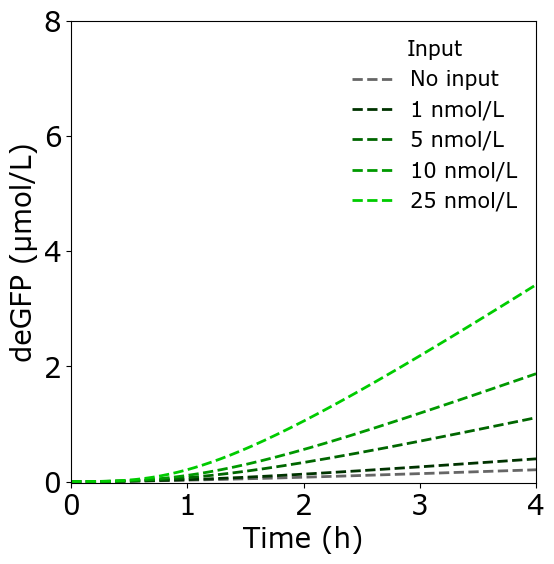

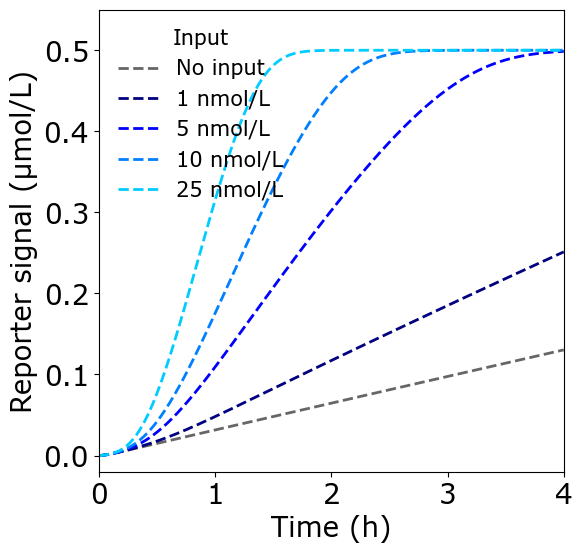

In [8]:
# Simulate
try:
    # Input templates
    IN1 = [0,1,5,10,25]

    idx_conditions = {'No input':[[0.4,0.4,0.4], '--'],
                      '1 nmol/L': [[0,0.2,0],'--'],
                      '5 nmol/L': [[0,0.4,0],'--'],
                      '10 nmol/L': [[0,0.6,0],'--'],
                      '25 nmol/L': [[0,0.8,0],'--']}

    for I1_conc, key in zip(IN1,idx_conditions.keys()):
        # Create an initial condition so A has a non-zero value
        initial_concentration_dict = {'dna_Input_1': I1_conc, 
                                      'dna_THErr_1_2nGFP':25,
                                      'dna_Reporter_2':500}
        
        # This function can also take a filename keyword to save the file at the same time
        R = CRN_ctRSD.simulate_with_bioscrape_via_sbml(timepoints = timepoints,
                                                    initial_condition_dict = initial_concentration_dict)
    
        # Example plotting in the subplots
        plt.plot(R['time']/3600, R['protein_GFP']/1000, label = key,
                 color = idx_conditions[key][0], linewidth = 2, linestyle = idx_conditions[key][1])
    
except ModuleNotFoundError:
    print("Plotting Modules not installed.")

FormatPlot(ylabel='deGFP (μmol/L)',ymax = 8, fig_name= 'Figure_2E_Extract_GFP')

try:

    idx_conditions = {'No input':[[0.4,0.4,0.4], '--'],
                      '1 nmol/L': [[0,0,0.5],'--'],
                      '5 nmol/L': [[0,0,1],'--'],
                      '10 nmol/L': [[0,0.5,1],'--'],
                      '25 nmol/L': [[0,0.8,1],'--']}

    for I1_conc, key in zip(IN1,idx_conditions.keys()):
            # Create an initial condition so A has a non-zero value
            initial_concentration_dict = {'dna_Input_1': I1_conc, 
                                        'dna_THErr_1_2nGFP':25,
                                        'dna_Reporter_2':500}
            
            # This function can also take a filename keyword to save the file at the same time
            R = CRN_ctRSD.simulate_with_bioscrape_via_sbml(timepoints = timepoints,
                                                        initial_condition_dict = initial_concentration_dict)
        
            # Example plotting in the subplots
            plt.figure(2)
            plt.plot(R['time']/3600, R['dna_Signal_2_ss']/1000, label = key,
                    color = idx_conditions[key][0], linewidth = 2, linestyle = idx_conditions[key][1])
    
except ModuleNotFoundError:
    print("Plotting Modules not installed.")

FormatPlot(ylabel='Reporter signal (μmol/L)',ymax = 0.55, fig_name= 'Figure_2E_Extract_MB')

## Genetically encoded RNA-based TMSE circuits in cells (E coli - SimpleTxTlDilutionMixture)

A simulation of a THE riboregulator from: https://www.biorxiv.org/content/10.1101/2025.09.24.678369v1.full. 

In [9]:
# Define initial DNA and Reporter RNA
sim_inputs = {'DNA_1': ['Input', 1]} # Input DNA
sim_gates = {'DNA_2':['THErr',1,[2,'GFP']]} # Gate DNA

# Components
step_tx0 =StrandExchangeMol(sim_inputs, material_type = 'dna', transcription=True)
step_tx1 =StrandExchangeMol(sim_gates, material_type = 'dna', transcription=True, rna_maturation = True,leak='ctRSDleak')

step_rz =RNAmaturation(step_tx1)

rna_TMSE = step_tx0.rna+step_tx1.rna+step_rz.rna
step_rsd = TMSE(rna_TMSE)
step_leak = LeakctRSD(step_tx1)

# Reactions
# Mechanism rz
mech_rz = MaturationO1()
rz_mechanisms = {mech_rz.mechanism_type: mech_rz}
# Mechanism strand displacement
mech_rsd = OneStepTMSE()
rsd_mechanisms = {mech_rsd.mechanism_type:mech_rsd}
# Mechanism leak
mech_leak = GateTxLeak()
leak_mechanisms = {mech_leak.mechanism_type:mech_leak}


# Parameters
ctRSD_parameters = {"ktx": 0.013, "leak_percentage": 0.03, "kmat": 0.00417, 
                    "kx":1e-06, "krev":2.7e-07, "krep":1e4/1e9, "ktl":.0005,"kdil":0.00025} 

# Make Mixture and Compile
M_ctRSD = SimpleTxTlDilutionMixture("Single_Gate_ctRSD_cells", components=[step_tx0.mol, step_tx1.mol, step_rz, step_rsd, step_leak, step_rsd.transcripts],
             parameters=ctRSD_parameters,
             mechanisms=rz_mechanisms|rsd_mechanisms|leak_mechanisms) #tx_mechanisms|

# Compile the CRN with Mixture.compile_crn
CRN_ctRSD = M_ctRSD.compile_crn()

# Print CRN reactions
print(CRN_ctRSD.pretty_print(show_rates = True, show_attributes = True, 
                       show_materials = True, show_keys = True))

Species(N = 9) = {
rna[THErr_1_2nGFP] (@ 0),  rna[THErr_1_2nGFP(pre)] (@ 0),  dna[THErr_1_2nGFP] (@ 0),  rna[Output_1_2nGFP(dummy)] (@ 0),  rna[Output_1_2] (@ 0),  rna[Input_1] (@ 0),  dna[Input_1] (@ 0),  protein[GFP] (@ 0),  rna[GFP] (@ 0),  
}

Reactions (19) = [
0. dna[Input_1] --> dna[Input_1]+rna[Input_1]
 Kf=k_forward * dna_Input_1
  k_forward=0.013
  found_key=(mech=None, partid=None, name=ktx).
  search_key=(mech=simple_transcription, partid=strong, name=ktx).

1. dna[THErr_1_2nGFP] --> dna[THErr_1_2nGFP]+rna[THErr_1_2nGFP(pre)]+rna[Output_1_2nGFP(dummy)]
 Kf=k_forward * dna_THErr_1_2nGFP
  k_forward=0.013
  found_key=(mech=None, partid=None, name=ktx).
  search_key=(mech=simple_transcription, partid=strong, name=ktx).

2. rna[THErr_1_2nGFP(pre)] --> rna[THErr_1_2nGFP]
 Kf=k_forward * rna_THErr_1_2nGFP_pre
  k_forward=0.00417
  found_key=(mech=None, partid=None, name=kmat).
  search_key=(mech=maturation, partid=HErr_1_2nGFP, name=kmat).

3. rna[Input_1]+rna[THErr_1_2nGFP] <-->

### Simulated using BioSCRAPE

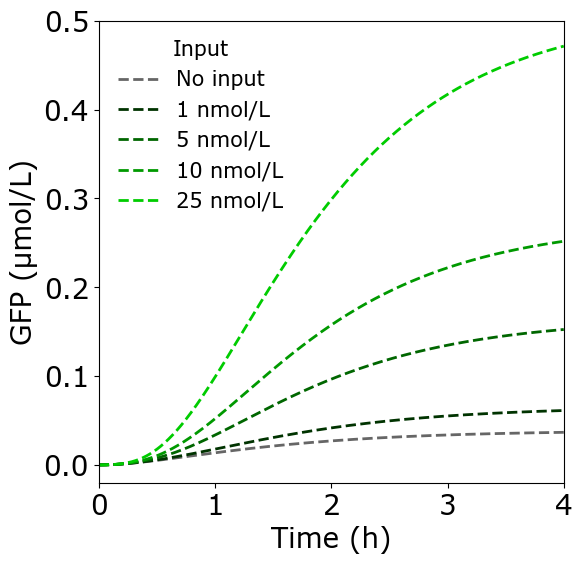

In [10]:
# Simulate
try:
    # Input templates
    IN1 = [0,1,5,10,25]

    idx_conditions = {'No input':[[0.4,0.4,0.4], '--'],
                      '1 nmol/L': [[0,0.2,0],'--'],
                      '5 nmol/L': [[0,0.4,0],'--'],
                      '10 nmol/L': [[0,0.6,0],'--'],
                      '25 nmol/L': [[0,0.8,0],'--']}
    
    for I1_conc, key in zip(IN1,idx_conditions.keys()):
        # Create an initial condition so A has a non-zero value
        initial_concentration_dict = {'dna_Input_1': I1_conc, 
                                      'dna_THErr_1_2nGFP':25}
        
        # This function can also take a filename keyword to save the file at the same time
        R = CRN_ctRSD.simulate_with_bioscrape_via_sbml(timepoints = timepoints,
                                                    initial_condition_dict = initial_concentration_dict)
    
        # Example plotting in the subplots
        plt.plot(R['time']/3600, R['protein_GFP']/1000, label = key,
                 color = idx_conditions[key][0], linewidth = 2, linestyle = idx_conditions[key][1])
    
except ModuleNotFoundError:
    print("Plotting Modules not installed.")

FormatPlot(ylabel='GFP (μmol/L)',ymax =0.5, fig_name= 'Figure_2E-cells')    

## Genetically encoded RNA-based TMSE circuits in cells (E coli - TxTlDilutionMixture)

A simulation of a THE riboregulator from: https://www.biorxiv.org/content/10.1101/2025.09.24.678369v1.full. 

In [11]:
# Define initial DNA and Reporter RNA
sim_inputs = {'DNA_1': ['Input', 1]} # Input DNA
sim_gates = {'DNA_2':['THErr',1,[2,'GFP']]} # Gate DNA

# Components
step_tx0 =StrandExchangeMol(sim_inputs, material_type = 'dna', transcription=True)
step_tx1 =StrandExchangeMol(sim_gates, material_type = 'dna', transcription=True, rna_maturation=True, leak='ctRSDleak')

step_rz =RNAmaturation(step_tx1)

rna_TMSE = step_tx0.rna+ step_tx1.rna+ step_rz.rna
step_rsd = TMSE(rna_TMSE)
step_leak = LeakctRSD(step_tx1)


# Reactions
# Mechanism rz
mech_rz = MaturationO1()
rz_mechanisms = {mech_rz.mechanism_type: mech_rz}
# Mechanism strand displacement
mech_rsd = OneStepTMSE()
rsd_mechanisms = {mech_rsd.mechanism_type:mech_rsd}
# Mechanism leak
mech_leak = GateTxLeak()
leak_mechanisms = {mech_leak.mechanism_type:mech_leak}


# Parameters
ctRSD_parameters = {"ktx": 0.013, "leak_percentage": 0.03, "kmat": 0.00417,
                    "kx":1e-06, "krev":2.7e-07, "krep":1e4/1e9,  "ktl":0.005, "kdil":0.00025,
                    ParameterKey(mechanism = "transcription_mm", part_id = None, name = "kb"):100,
                    ParameterKey(mechanism = "transcription_mm", part_id = None, name = "ku"):.5,
                    ParameterKey(mechanism = "translation_mm", part_id = None, name = "kb"):100,
                    ParameterKey(mechanism = "translation_mm", part_id = None, name = "ku"): 5,
                    ParameterKey(mechanism = "rna_degredation_mm", part_id = None, name = "kb"):100,
                    ParameterKey(mechanism = "rna_degredation_mm", part_id = None, name = "ku"):10,
                    ParameterKey(mechanism = "rna_degredation_mm", part_id = None, name = "kdeg"):.0001,
                    }

# Make Mixture and Compile
M_ctRSD = TxTlDilutionMixture("Single_Gate_ctRSD_cells2", components=[step_tx0.mol, step_tx1.mol, step_rz, step_rsd, step_leak, step_rsd.transcripts],
             parameters=ctRSD_parameters,
             mechanisms=rz_mechanisms|rsd_mechanisms|leak_mechanisms)

# Compile the CRN with Mixture.compile_crn
CRN_ctRSD = M_ctRSD.compile_crn()

# Print CRN reactions
print(CRN_ctRSD.pretty_print(show_rates = True, show_attributes = True, 
                       show_materials = True, show_keys = False))

Species(N = 29) = {
complex[protein[Ribo]:rna[cellular_processes]] (@ 0),  complex[protein[Ribo]:rna[GFP]] (@ 0),  complex[protein[RNAase]:rna[cellular_processes]] (@ 0),  complex[protein[RNAase]:rna[THErr_1_2nGFP]] (@ 0),  complex[protein[RNAase]:rna[THErr_1_2nGFP]] (@ 0),  complex[protein[RNAase]:rna[Output_1_2nGFP]] (@ 0),  complex[protein[RNAase]:rna[Output_1_2]] (@ 0),  complex[protein[RNAase]:rna[Input_1]] (@ 0),  complex[protein[RNAase]:rna[GFP]] (@ 0),  complex[dna[cellular_processes]:protein[RNAP]] (@ 0),  complex[dna[THErr_1_2nGFP]:protein[RNAP]] (@ 0),  complex[dna[Input_1]:protein[RNAP]] (@ 0),  complex[complex[protein[Ribo]:rna[cellular_processes]]:protein[RNAase]] (@ 0),  complex[complex[protein[Ribo]:rna[GFP]]:protein[RNAase]] (@ 0),  protein[cellular_processes] (@ 0),  rna[cellular_processes] (@ 0),  dna[cellular_processes] (@ 0),  rna[THErr_1_2nGFP] (@ 0),  rna[THErr_1_2nGFP(pre)] (@ 0),  dna[THErr_1_2nGFP] (@ 0),  protein[Ribo(machinery)] (@ 0),  protein[RNAase(machin

### Simulated using BioSCRAPE

c:\Users\zej1\AppData\Local\miniforge3\envs\ctRSD_models\Lib\site-packages\biocrnpyler\core\chemical_reaction_network.py:511: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  result = py_simulate_model(
c:\Users\zej1\AppData\Local\miniforge3\envs\ctRSD_models\Lib\site-packages\biocrnpyler\core\chemical_reaction_network.py:511: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  result = py_simulate_model(
c:\Users\zej1\AppData\Local\miniforge3\envs\ctRSD_models\Lib\site-packages\biocrnpyler\core\chemical_reaction_network.py:511: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  result = py_simulate_model(
c:\Users\zej1\AppData\Local\miniforge3\envs\ctRSD_models\Lib\site-packages\biocrnpyler\core\chemical_reaction_network.py:511: ODEintWarning: E

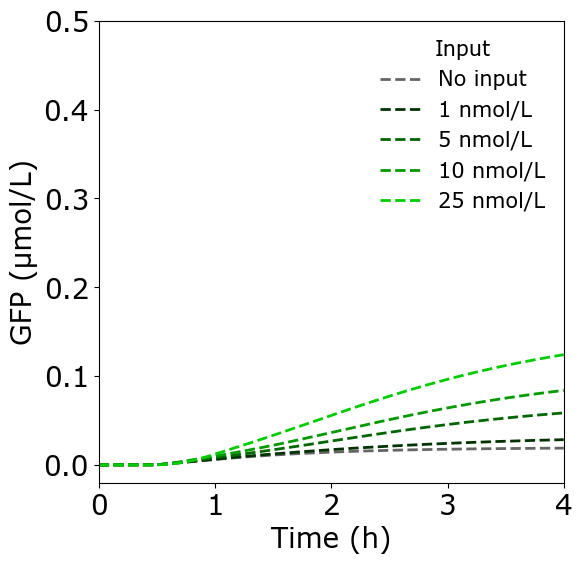

In [12]:
# Simulate
initial_concentration_dict= {'protein_RNAP_machinery': 0.00933*1000, #nM
                                      'protein_Ribo_machinery': 0.0273*1000,#nM
                                      'protein_RNAase_machinery': 20.2*10,
                                      "dna_cellular_processes":5,"rna_cellular_processes":5,"protein_cellular_processes":5}
try:
    # Input templates
    IN1 = [0,1,5,10,25]

    idx_conditions = {'No input':[[0.4,0.4,0.4], '--'],
                      '1 nmol/L': [[0,0.2,0],'--'],
                      '5 nmol/L': [[0,0.4,0],'--'],
                      '10 nmol/L': [[0,0.6,0],'--'],
                      '25 nmol/L': [[0,0.8,0],'--']}
    

    for I1_conc, key in zip(IN1,idx_conditions.keys()):
        # Create an initial condition so A has a non-zero value
        initial_concentration_dict.update({'dna_Input_1': I1_conc, 
                                      'dna_THErr_1_2nGFP':25})
        
        # This function can also take a filename keyword to save the file at the same time
        R = CRN_ctRSD.simulate_with_bioscrape_via_sbml(timepoints = timepoints,
                                                    initial_condition_dict = initial_concentration_dict)
    
        # Example plotting in the subplots
        plt.plot(R['time']/3600, R['protein_GFP']/1000, label = key,
                 color = idx_conditions[key][0], linewidth = 2, linestyle = idx_conditions[key][1])
    
except ModuleNotFoundError:
    print("Plotting Modules not installed.")

FormatPlot(ylabel='GFP (μmol/L)',ymax = 0.5, fig_name= 'Figure_2D_Cells_GFP2')



# Computing environment

In [13]:
%load_ext watermark
%watermark -v -p bioscrape,bokeh,jupyterlab,biocrnpyler

Python implementation: CPython
Python version       : 3.12.12
IPython version      : 9.12.0

bioscrape  : 1.2.1
bokeh      : 3.9.1
jupyterlab : 4.5.0
biocrnpyler: 1.3.2

